# Spectral Indices and Land-Cover Classification

This notebook calculates spectral indices and performs land-cover classification for Lublin in 2006, 2016 and 2026.

The workflow:
- reconstructs the preprocessed Landsat composites,
- calculates NDVI and NDBI,
- explores spectral structure using K-means clustering,
- evaluates the appropriate number of clusters,
- loads manually prepared land-cover training polygons,
- trains a supervised Random Forest classifier,
- validates the classifier using an independent polygon-level train/test split,
- applies the final classifier consistently to all three analysed years.

Four land-cover classes are used:
- vegetation,
- built-up,
- other,
- water.

## Environment and project setup

The required Python libraries and reusable Earth Engine helper functions are loaded. Project paths are defined relative to the repository root.

In [1]:
from pathlib import Path
import sys
import json

import ee
import geemap
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

from gee_utils import (
    preprocess_landsat5,
    preprocess_landsat8,
    create_composite,
    add_indices,
    split_class,
    sample_year
)

ee.Initialize()
print("Earth Engine initialized")

Earth Engine initialized


## Study area

The previously generated administrative boundary of Lublin is loaded and converted to WGS84. The resulting geometry defines the common Area of Interest used for all three analysed years.

In [2]:
CITY_PATH = (
    PROJECT_ROOT
    / "data"
    / "boundaries"
    / "city"
    / "lublin_city_boundary.shp"
)

city = gpd.read_file(CITY_PATH).to_crs(epsg=4326)

city_geojson = json.loads(city.to_json())

aoi = ee.Geometry(
    city_geojson["features"][0]["geometry"]
)

print("AOI:", aoi.getInfo()["type"])

AOI: Polygon


## Landsat composites

The same preprocessing workflow and summer observation window used in the data-preparation notebook are applied here to reconstruct the 2006, 2016 and 2026 composites.

Landsat 5 TM is used for 2006, while Landsat 8 OLI is used for 2016 and 2026.

In [3]:
composite_2006 = create_composite(
    collection_id="LANDSAT/LT05/C02/T1_L2",
    start_date="2006-06-01",
    end_date="2006-09-01",
    aoi=aoi,
    preprocess_func=preprocess_landsat5
)

composite_2016 = create_composite(
    collection_id="LANDSAT/LC08/C02/T1_L2",
    start_date="2016-06-01",
    end_date="2016-09-01",
    aoi=aoi,
    preprocess_func=preprocess_landsat8
)

composite_2026 = create_composite(
    collection_id="LANDSAT/LC08/C02/T1_L2",
    start_date="2026-06-01",
    end_date="2026-09-01",
    aoi=aoi,
    preprocess_func=preprocess_landsat8
)

print("Composites created")

Composites created


## Spectral indices

Two spectral indices are added to each composite.

### NDVI

The Normalized Difference Vegetation Index is calculated as:

`NDVI = (NIR - Red) / (NIR + Red)`

Higher values generally indicate stronger photosynthetically active vegetation.

### NDBI

The Normalized Difference Built-up Index is calculated as:

`NDBI = (SWIR1 - NIR) / (SWIR1 + NIR)`

Higher values can indicate built-up or other dry, non-vegetated surfaces.

Neither index is treated as a direct land-cover class. Both are used together with the optical Landsat bands as predictor variables for classification.

In [4]:
composite_2006_idx = add_indices(composite_2006)
composite_2016_idx = add_indices(composite_2016)
composite_2026_idx = add_indices(composite_2026)

print("2006:", composite_2006_idx.bandNames().getInfo())
print("2016:", composite_2016_idx.bandNames().getInfo())
print("2026:", composite_2026_idx.bandNames().getInfo())

2006: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'NDVI', 'NDBI']
2016: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'NDVI', 'NDBI']
2026: ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'NDVI', 'NDBI']


### NDVI visualization

NDVI is displayed for all three analysed years using the same visualization range to support visual comparison over time.

In [5]:
ndvi_vis = {
    "min": -0.2,
    "max": 0.8,
    "palette": [
        "brown",
        "yellow",
        "lightgreen",
        "green",
        "darkgreen"
    ]
}

Map_ndvi = geemap.Map()
Map_ndvi.centerObject(aoi, 11)

Map_ndvi.addLayer(
    composite_2006_idx.select("NDVI"),
    ndvi_vis,
    "NDVI 2006"
)

Map_ndvi.addLayer(
    composite_2016_idx.select("NDVI"),
    ndvi_vis,
    "NDVI 2016"
)

Map_ndvi.addLayer(
    composite_2026_idx.select("NDVI"),
    ndvi_vis,
    "NDVI 2026"
)

Map_ndvi

Map(center=[51.225732957054035, 22.556598958902953], controls=(WidgetControl(options=['position', 'transparent…

### NDBI visualization

NDBI is displayed for all three analysed years using a common visualization range.

In [6]:
ndbi_vis = {
    "min": -0.4,
    "max": 0.4,
    "palette": [
        "darkblue",
        "lightblue",
        "white",
        "orange",
        "red"
    ]
}

Map_ndbi = geemap.Map()
Map_ndbi.centerObject(aoi, 11)

Map_ndbi.addLayer(
    composite_2006_idx.select("NDBI"),
    ndbi_vis,
    "NDBI 2006"
)

Map_ndbi.addLayer(
    composite_2016_idx.select("NDBI"),
    ndbi_vis,
    "NDBI 2016"
)

Map_ndbi.addLayer(
    composite_2026_idx.select("NDBI"),
    ndbi_vis,
    "NDBI 2026"
)

Map_ndbi

Map(center=[51.225732957054035, 22.556598958902953], controls=(WidgetControl(options=['position', 'transparent…

### Spectral-index summary

Robust summary statistics are calculated using the 2nd, 50th and 98th percentiles together with the mean.

Percentiles are preferred over absolute minimum and maximum values because normalized-difference indices can produce extreme numerical outliers when the denominator approaches zero.

In [7]:
def index_stats(image, band, aoi):
    stats = (
        image.select(band)
        .reduceRegion(
            reducer=ee.Reducer.percentile([2, 50, 98]).combine(
                reducer2=ee.Reducer.mean(),
                sharedInputs=True
            ),
            geometry=aoi,
            scale=30,
            maxPixels=1e9
        )
    )

    return stats.getInfo()


for year, image in [
    (2006, composite_2006_idx),
    (2016, composite_2016_idx),
    (2026, composite_2026_idx)
]:
    print(year, "NDVI:", index_stats(image, "NDVI", aoi))
    print(year, "NDBI:", index_stats(image, "NDBI", aoi))

2006 NDVI: {'NDVI_mean': 0.522407672185203, 'NDVI_p2': 0.1582133296831603, 'NDVI_p50': 0.521502957593898, 'NDVI_p98': 0.8338849381904272}
2006 NDBI: {'NDBI_mean': -0.19899553399674888, 'NDBI_p2': -0.448637879464347, 'NDBI_p50': -0.1835678409002786, 'NDBI_p98': 0.019433036529649127}
2016 NDVI: {'NDVI_mean': 0.6146156285691284, 'NDVI_p2': 0.05064243838287348, 'NDVI_p50': 0.6721039794940468, 'NDVI_p98': 0.8915472807270721}
2016 NDBI: {'NDBI_mean': -0.24795212015804868, 'NDBI_p2': -0.5066993446238851, 'NDBI_p50': -0.24218589478406358, 'NDBI_p98': 0.0385980477549417}
2026 NDVI: {'NDVI_mean': 0.5731854121412221, 'NDVI_p2': 0.3448825065014591, 'NDVI_p50': 0.7057389918663507, 'NDVI_p98': 0.7057389918663507}
2026 NDBI: {'NDBI_mean': -0.20685270414991855, 'NDBI_p2': -0.22983711409653443, 'NDBI_p50': -0.22983711409653443, 'NDBI_p98': 0.05096824509133699}


## Classification predictor variables

The classification uses six harmonized Landsat reflectance bands together with NDVI and NDBI.

The same predictor set is used for all analysed years to maintain methodological consistency.

In [8]:
predictor_bands = [
    "blue",
    "green",
    "red",
    "nir",
    "swir1",
    "swir2",
    "NDVI",
    "NDBI"
]

## Unsupervised classification — K-means

K-means clustering is used as an exploratory unsupervised classification method.

A random sample of 5,000 pixels is collected from each analysed year, producing a combined sample of approximately 15,000 observations. Using a combined multi-year sample allows the clustering structure to represent the full analysed period rather than a single year.

In [9]:
sample_2006 = (
    composite_2006_idx
    .select(predictor_bands)
    .sample(
        region=aoi,
        scale=30,
        numPixels=5000,
        seed=42,
        geometries=False
    )
)

sample_2016 = (
    composite_2016_idx
    .select(predictor_bands)
    .sample(
        region=aoi,
        scale=30,
        numPixels=5000,
        seed=42,
        geometries=False
    )
)

sample_2026 = (
    composite_2026_idx
    .select(predictor_bands)
    .sample(
        region=aoi,
        scale=30,
        numPixels=5000,
        seed=42,
        geometries=False
    )
)

training_kmeans = (
    sample_2006
    .merge(sample_2016)
    .merge(sample_2026)
)

print("Number of samples:", training_kmeans.size().getInfo())

Number of samples: 15000


### Standardization of predictor variables

The sampled predictor values are transferred to a Pandas DataFrame and standardized using `StandardScaler`.

Standardization is necessary because K-means is based on Euclidean distance and is sensitive to differences in variable scales.

In [10]:
training_df = ee.data.computeFeatures({
    "expression": training_kmeans,
    "fileFormat": "PANDAS_DATAFRAME"
})

training_df = training_df[predictor_bands]

print(training_df.shape)
display(training_df.head())

(15000, 8)


,blue,green,red,nir,swir1,swir2,NDVI,NDBI
0,0.060123,0.083442,0.074175,0.255978,0.172735,0.110860,0.550662,-0.194169
1,0.064976,0.091390,0.099379,0.193621,0.165049,0.123084,0.321647,-0.079662
2,0.109141,0.134538,0.127277,0.204759,0.219609,0.195409,0.233352,0.034993
3,0.043939,0.061374,0.055888,0.231200,0.135610,0.079867,0.610659,-0.260598
4,0.043127,0.071604,0.067314,0.291425,0.235160,0.119536,0.624720,-0.106849


In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(training_df)

print("Means after standardization:")
print(X_scaled.mean(axis=0).round(3))

print("Standard deviations after standardization:")
print(X_scaled.std(axis=0).round(3))

Means after standardization:
[ 0. -0. -0. -0. -0. -0. -0.  0.]
Standard deviations after standardization:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [12]:
means = scaler.mean_.tolist()
stds = scaler.scale_.tolist()

print("Means:", means)
print("Stds:", stds)

Means: [0.05148963583333333, 0.08159109, 0.07917856358333333, 0.29944283308333336, 0.19383972466666669, 0.12102312275, 0.5703057008136511, -0.21588927912206443]
Stds: [0.024752906926112726, 0.03075736811904493, 0.041381397964568814, 0.07980514024941596, 0.05612816585326376, 0.05096496267859129, 0.20924156591873733, 0.18900434386079654]


### Selection of the number of clusters

Candidate values from `k = 2` to `k = 8` are evaluated using two complementary criteria:

- within-cluster sum of squares (inertia), used for the elbow method,
- silhouette score, used to assess cluster separation.

Although `k = 2` produces the highest silhouette score, it is too coarse for the intended land-cover interpretation. The elbow occurs around three to four clusters, and `k = 4` provides the best silhouette score among the practical solutions with more than two clusters.

Therefore, four clusters are selected as a compromise between statistical separation and thematic usefulness.

In [13]:
k_values = range(2, 9)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

results_k = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette": silhouette_scores
})

results_k

,k,inertia,silhouette
0,2,70823.493902,0.382447
1,3,55618.068834,0.336091
2,4,46376.597752,0.339516
3,5,39852.085559,0.301905
4,6,34275.466138,0.311952
5,7,29578.450078,0.312470
6,8,26076.722484,0.295143


### Elbow and silhouette diagnostics

The inertia and silhouette results are visualized to support the final selection of four clusters.

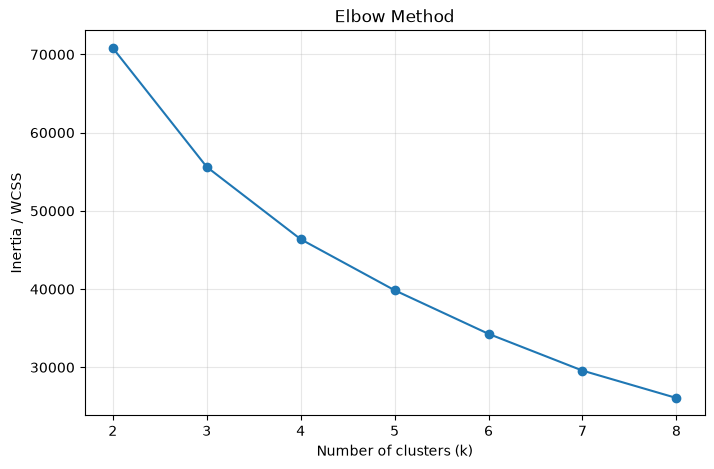

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(
    results_k["k"],
    results_k["inertia"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method")
plt.grid(alpha=0.3)
plt.show()

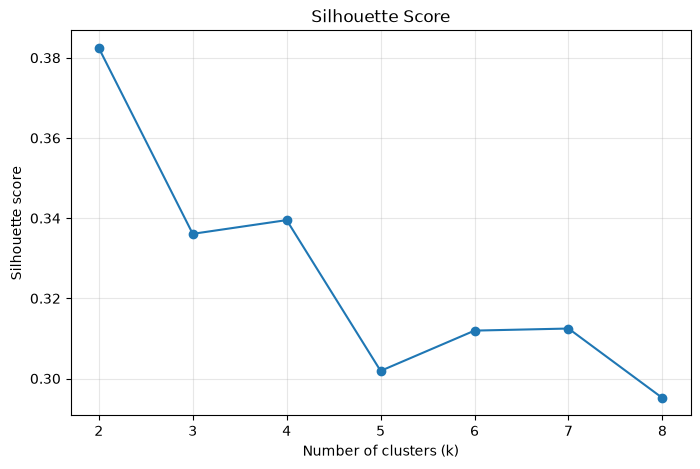

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(
    results_k["k"],
    results_k["silhouette"],
    marker="o"
)

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score")
plt.grid(alpha=0.3)
plt.show()

### Apply the standardization to Earth Engine images

The means and standard deviations calculated from the combined sample are applied to the full Earth Engine predictor images so that clustering is performed in the same standardized feature space.

In [16]:
def standardize_image(image, bands, means, stds):
    mean_image = ee.Image.constant(means).rename(bands)
    std_image = ee.Image.constant(stds).rename(bands)

    return (
        image
        .select(bands)
        .subtract(mean_image)
        .divide(std_image)
        .rename(bands)
    )

In [17]:
standardized_2006 = standardize_image(
    composite_2006_idx,
    predictor_bands,
    means,
    stds
)

standardized_2016 = standardize_image(
    composite_2016_idx,
    predictor_bands,
    means,
    stds
)

standardized_2026 = standardize_image(
    composite_2026_idx,
    predictor_bands,
    means,
    stds
)

In [18]:
sample_std_2006 = standardized_2006.sample(
    region=aoi,
    scale=30,
    numPixels=5000,
    seed=42,
    geometries=False
)

sample_std_2016 = standardized_2016.sample(
    region=aoi,
    scale=30,
    numPixels=5000,
    seed=42,
    geometries=False
)

sample_std_2026 = standardized_2026.sample(
    region=aoi,
    scale=30,
    numPixels=5000,
    seed=42,
    geometries=False
)

training_std = (
    sample_std_2006
    .merge(sample_std_2016)
    .merge(sample_std_2026)
)

print(training_std.size().getInfo())

15000


### Final K-means model

A single four-cluster K-means model is trained using standardized samples from all three years and is then applied consistently to the 2006, 2016 and 2026 composites.

In [19]:
kmeans_final = (
    ee.Clusterer.wekaKMeans(
        nClusters=4,
        distanceFunction="Euclidean",
        seed=42
    )
    .train(
        features=training_std,
        inputProperties=predictor_bands
    )
)

In [20]:
kmeans_2006 = standardized_2006.cluster(kmeans_final).clip(aoi)
kmeans_2016 = standardized_2016.cluster(kmeans_final).clip(aoi)
kmeans_2026 = standardized_2026.cluster(kmeans_final).clip(aoi)

In [21]:
cluster_vis = {
    "min": 0,
    "max": 3,
    "palette": [
        "red",
        "blue",
        "green",
        "yellow"
    ]
}

Map_kmeans = geemap.Map()
Map_kmeans.centerObject(aoi, 11)

Map_kmeans.addLayer(kmeans_2006, cluster_vis, "K-means 2006")
Map_kmeans.addLayer(kmeans_2016, cluster_vis, "K-means 2016")
Map_kmeans.addLayer(kmeans_2026, cluster_vis, "K-means 2026")

Map_kmeans

Map(center=[51.225732957054035, 22.556598958902875], controls=(WidgetControl(options=['position', 'transparent…

### Cluster interpretation

Mean spectral and index values are calculated for each cluster to support their interpretation.

K-means clusters are spectral groups and are not assumed to correspond directly to semantic land-cover classes. The results are therefore used as an exploratory comparison rather than as the final classification product.

In [22]:
def cluster_stats(image_with_indices, cluster_image, aoi, n_clusters=4):
    bands = [
        "NDVI",
        "NDBI",
        "red",
        "nir",
        "swir1"
    ]

    results = []

    for cluster_id in range(n_clusters):
        mask = cluster_image.eq(cluster_id)

        stats = (
            image_with_indices
            .select(bands)
            .updateMask(mask)
            .reduceRegion(
                reducer=ee.Reducer.mean(),
                geometry=aoi,
                scale=30,
                maxPixels=1e9
            )
            .getInfo()
        )

        stats["cluster"] = cluster_id
        results.append(stats)

    return results

In [23]:
stats_2006 = cluster_stats(
    composite_2006_idx,
    kmeans_2006,
    aoi
)

stats_2016 = cluster_stats(
    composite_2016_idx,
    kmeans_2016,
    aoi
)

stats_2026 = cluster_stats(
    composite_2026_idx,
    kmeans_2026,
    aoi
)

In [24]:
df_2006 = pd.DataFrame(stats_2006)
df_2006["year"] = 2006

df_2016 = pd.DataFrame(stats_2016)
df_2016["year"] = 2016

df_2026 = pd.DataFrame(stats_2026)
df_2026["year"] = 2026

cluster_summary = pd.concat(
    [df_2006, df_2016, df_2026],
    ignore_index=True
)

cluster_summary = cluster_summary[
    [
        "year",
        "cluster",
        "NDVI",
        "NDBI",
        "red",
        "nir",
        "swir1"
    ]
]

cluster_summary

,year,cluster,NDVI,NDBI,red,nir,swir1
0,2006,0,0.738758,-0.337171,0.053136,0.349850,0.174445
1,2006,1,0.482882,-0.152201,0.102305,0.299644,0.218424
2,2006,2,0.329725,-0.050869,0.158219,0.316955,0.284739
3,2006,3,0.503175,-0.307247,0.058892,0.198995,0.112796
4,2016,0,0.782689,-0.353331,0.044313,0.366247,0.174812
5,2016,1,0.494958,-0.128886,0.090452,0.275975,0.209990
6,2016,2,0.267874,-0.019811,0.170698,0.297150,0.283567
7,2016,3,0.500790,-0.265756,0.053565,0.193434,0.120936
8,2026,0,0.792298,-0.352596,0.041973,0.363522,0.173602
9,2026,1,0.485213,-0.119918,0.094096,0.279586,0.216668


In [25]:
rf_vis = {
    "bands": ["red", "green", "blue"],
    "min": 0.02,
    "max": 0.30
}

Map_rf = geemap.Map()
Map_rf.centerObject(aoi, 12)

Map_rf.addLayer(
    composite_2026_idx,
    rf_vis,
    "RGB 2026"
)

Map_rf.addLayer(
    composite_2026_idx.select("NDVI"),
    {
        "min": -0.2,
        "max": 0.8,
        "palette": ["brown", "yellow", "lightgreen", "green", "darkgreen"]
    },
    "NDVI 2026",
    False
)

Map_rf.addLayer(
    composite_2026_idx.select("NDBI"),
    {
        "min": -0.4,
        "max": 0.4,
        "palette": ["darkblue", "lightblue", "white", "orange", "red"]
    },
    "NDBI 2026",
    False
)

Map_rf

Map(center=[51.225732957054035, 22.556598958902875], controls=(WidgetControl(options=['position', 'transparent…

## Supervised classification — Random Forest

### Training data

Training polygons were manually digitized using the 2026 RGB, NDVI and NDBI layers as visual references.

Four semantic land-cover classes were defined:

- `0` — vegetation,
- `1` — built-up,
- `2` — other,
- `3` — water.

The polygons were created as small, spatially distributed and internally homogeneous training areas. Their consistency was also visually checked against the 2006 and 2016 composites.

The digitization step was performed once during training-data preparation. To keep this notebook reproducible, the resulting polygons are stored as GeoJSON files in `data/training/` and are loaded directly below rather than being redrawn during every execution.

In [26]:
TRAINING_DIR = PROJECT_ROOT / "data" / "training"
#TRAINING_DIR.mkdir(parents=True, exist_ok=True)

In [27]:
# Load the saved training polygons
vegetation_gdf = gpd.read_file(TRAINING_DIR / "vegetation.geojson")
built_up_gdf   = gpd.read_file(TRAINING_DIR / "built_up.geojson")
other_gdf      = gpd.read_file(TRAINING_DIR / "other.geojson")
water_gdf      = gpd.read_file(TRAINING_DIR / "water.geojson")

training_gdf = gpd.GeoDataFrame(
    pd.concat(
        [vegetation_gdf, built_up_gdf, other_gdf, water_gdf],
        ignore_index=True
    ),
    crs=vegetation_gdf.crs
)

print(training_gdf["class_name"].value_counts())
print("Total:", len(training_gdf))

class_name
vegetation    18
water         13
built_up      12
other          9
Name: count, dtype: int64
Total: 52


In [28]:
training_gdf = training_gdf.to_crs(epsg=4326)

training_fc = geemap.geopandas_to_ee(training_gdf)

In [29]:
Map_check = geemap.Map()
Map_check.centerObject(aoi, 11)

Map_check.addLayer(
    composite_2006_idx,
    rf_vis,
    "RGB 2006",
    False
)

Map_check.addLayer(
    composite_2016_idx,
    rf_vis,
    "RGB 2016",
    False
)

Map_check.addLayer(
    composite_2026_idx,
    rf_vis,
    "RGB 2026",
    True
)

Map_check.addLayer(
    training_fc.style(
        color="yellow",
        fillColor="00000000",
        width=2
    ),
    {},
    "Training polygons"
)

Map_check

Map(center=[51.225732957054035, 22.556598958902953], controls=(WidgetControl(options=['position', 'transparent…

In [30]:
predictor_bands = [
    "blue", "green", "red",
    "nir", "swir1", "swir2",
    "NDVI", "NDBI"
]

samples_2006 = composite_2006_idx.select(predictor_bands).sampleRegions(
    collection=training_fc,
    properties=["class", "class_name"],
    scale=30,
    geometries=True
)

samples_2016 = composite_2016_idx.select(predictor_bands).sampleRegions(
    collection=training_fc,
    properties=["class", "class_name"],
    scale=30,
    geometries=True
)

samples_2026 = composite_2026_idx.select(predictor_bands).sampleRegions(
    collection=training_fc,
    properties=["class", "class_name"],
    scale=30,
    geometries=True
)

training_samples = (
    samples_2006
    .merge(samples_2016)
    .merge(samples_2026)
)

print("Number of training pixels:", training_samples.size().getInfo())

Number of training pixels: 3354


In [31]:
class_histogram = training_samples.aggregate_histogram("class").getInfo()
print(class_histogram)

{'0': 1170, '1': 693, '2': 651, '3': 840}


### Independent polygon-level train/test split

The training polygons are split into training and testing subsets separately for each class.

The split is performed at polygon level rather than at individual pixel level. This reduces spatial leakage between neighbouring pixels belonging to the same manually digitized polygon and provides a more conservative validation design.

In [32]:

train_0, test_0 = split_class(training_fc, 0, 5, 42)
train_1, test_1 = split_class(training_fc, 1, 4, 43)
train_2, test_2 = split_class(training_fc, 2, 3, 44)
train_3, test_3 = split_class(training_fc, 3, 4, 45)

train_polygons = (
    train_0
    .merge(train_1)
    .merge(train_2)
    .merge(train_3)
)

test_polygons = (
    test_0
    .merge(test_1)
    .merge(test_2)
    .merge(test_3)
)

print("Training polygons:", train_polygons.size().getInfo())
print("Testing polygons:", test_polygons.size().getInfo())

print(
    "Training classes:",
    train_polygons.aggregate_histogram("class").getInfo()
)

print(
    "Testing classes:",
    test_polygons.aggregate_histogram("class").getInfo()
)

Training polygons: 36
Testing polygons: 16
Training classes: {'0': 13, '1': 8, '2': 6, '3': 9}
Testing classes: {'0': 5, '1': 4, '2': 3, '3': 4}


In [33]:
train_2006 = sample_year(
    composite_2006_idx,
    train_polygons,
    predictor_bands
)

train_2016 = sample_year(
    composite_2016_idx,
    train_polygons,
    predictor_bands
)

train_2026 = sample_year(
    composite_2026_idx,
    train_polygons,
    predictor_bands
)

train_samples = (
    train_2006
    .merge(train_2016)
    .merge(train_2026)
)

### Extract training and testing pixels

Predictor values are extracted independently from the training and testing polygons for all three years.

Samples from 2006, 2016 and 2026 are merged so that a single classifier can learn from the spectral conditions present across the complete time series.

In [34]:
test_2006 = sample_year(
    composite_2006_idx,
    test_polygons,
    predictor_bands
)
test_2016 = sample_year(
    composite_2016_idx,
    test_polygons,
    predictor_bands
)
test_2026 = sample_year(
    composite_2026_idx,
    test_polygons,
    predictor_bands
)
test_samples = (
    test_2006
    .merge(test_2016)
    .merge(test_2026)
)

In [35]:
print("Train pixels:", train_samples.size().getInfo())
print("Test pixels:", test_samples.size().getInfo())

print(
    "Train classes:",
    train_samples.aggregate_histogram("class").getInfo()
)

print(
    "Test classes:",
    test_samples.aggregate_histogram("class").getInfo()
)

Train pixels: 2202
Test pixels: 1152
Train classes: {'0': 882, '1': 471, '2': 501, '3': 348}
Test classes: {'0': 288, '1': 222, '2': 150, '3': 492}


### Random Forest model

A single Random Forest classifier with 200 trees is trained on the combined multi-year training sample.

Using one common classifier for 2006, 2016 and 2026 improves temporal consistency and avoids introducing differences caused by independently trained year-specific models.

In [36]:
rf_classifier = ee.Classifier.smileRandomForest(
    numberOfTrees=200,
    seed=42
).train(
    features=train_samples,
    classProperty="class",
    inputProperties=predictor_bands
)

## Random Forest validation

The independent testing sample is classified using the trained Random Forest model.

Model performance is evaluated using:
- confusion matrix,
- overall accuracy,
- Cohen's kappa,
- producer's accuracy,
- user's accuracy.

In [37]:
test_classified = test_samples.classify(rf_classifier)

confusion_matrix = test_classified.errorMatrix(
    actual="class",
    predicted="classification"
)

print("Confusion matrix:")
print(confusion_matrix.getInfo())

print("Overall accuracy:")
print(confusion_matrix.accuracy().getInfo())

print("Kappa:")
print(confusion_matrix.kappa().getInfo())

Confusion matrix:
[[272, 2, 10, 4], [0, 218, 4, 0], [21, 4, 125, 0], [0, 0, 0, 492]]
Overall accuracy:
0.9609375
Kappa:
0.9441445518311407


## Final land-cover classifications

The validated Random Forest model is applied to the predictor composites for 2006, 2016 and 2026.

The same classifier and class definitions are used for all years, producing temporally comparable land-cover maps.

In [38]:
rf_2006 = (
    composite_2006_idx
    .select(predictor_bands)
    .classify(rf_classifier)
    .clip(aoi)
)

rf_2016 = (
    composite_2016_idx
    .select(predictor_bands)
    .classify(rf_classifier)
    .clip(aoi)
)

rf_2026 = (
    composite_2026_idx
    .select(predictor_bands)
    .classify(rf_classifier)
    .clip(aoi)
)

### Visual inspection of the final classification

The classified maps are visually inspected to verify that the spatial distribution of vegetation, built-up areas, other surfaces and water is consistent with the underlying Landsat composites.

In [39]:
rf_vis = {
    "min": 0,
    "max": 3,
    "palette": [
        "2E8B57",  # 0 vegetation
        "D73027",  # 1 built_up
        "D9B38C",  # 2 other
        "2166AC"   # 3 water
    ]
}

Map_rf_results = geemap.Map()
Map_rf_results.centerObject(aoi, 11)

Map_rf_results.addLayer(rf_2006, rf_vis, "RF 2006")
Map_rf_results.addLayer(rf_2016, rf_vis, "RF 2016", False)
Map_rf_results.addLayer(rf_2026, rf_vis, "RF 2026", False)

Map_rf_results

Map(center=[51.225732957054035, 22.556598958902875], controls=(WidgetControl(options=['position', 'transparent…

In [40]:
producers_accuracy = confusion_matrix.producersAccuracy().getInfo()
users_accuracy = confusion_matrix.consumersAccuracy().getInfo()

print("Producer's Accuracy:")
print(producers_accuracy)

print("User's Accuracy:")
print(users_accuracy)

Producer's Accuracy:
[[0.9444444444444444], [0.9819819819819819], [0.8333333333333334], [1]]
User's Accuracy:
[[0.9283276450511946, 0.9732142857142857, 0.8992805755395683, 0.9919354838709677]]


In [41]:
class_names = ["vegetation", "built_up", "other", "water"]

validation_df = pd.DataFrame({
    "class": class_names,
    "producer_accuracy": [x[0] for x in producers_accuracy],
    "user_accuracy": users_accuracy[0]
})

validation_df

,class,producer_accuracy,user_accuracy
0,vegetation,0.944444,0.928328
1,built_up,0.981982,0.973214
2,other,0.833333,0.899281
3,water,1.000000,0.991935


In [42]:
print("Overall Accuracy:", confusion_matrix.accuracy().getInfo())
print("Kappa:", confusion_matrix.kappa().getInfo())

Overall Accuracy: 0.9609375
Kappa: 0.9441445518311407


## Output

This notebook produces consistent land-cover classifications for Lublin in 2006, 2016 and 2026 using four classes:

- vegetation,
- built-up,
- other,
- water.

K-means is retained as an exploratory unsupervised comparison method, while the validated Random Forest classification is selected as the final dataset for change detection.

The next notebook uses the Random Forest classifications to quantify class transitions and identify spatial patterns of land-cover change between 2006, 2016 and 2026.